# Spam Mail Detector

## Objective
Build a machine learning classifier that identifies whether an email is spam or ham (non-spam) using its text.

## 1. Import required basic Libraries

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Dataset

In [7]:
# Load the email dataset
emails = pd.read_csv("../data/emails.csv")

# Display basic dataset information
print("Dataset shape:", emails.shape)
print("Column names:", emails.columns.tolist())

# Display the first five rows
emails.head()

Dataset shape: (5728, 2)
Column names: ['text', 'spam']


,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


## 3. Explore the Dataset

In [8]:
# Check data types, missing values, duplicates, and class balance

print("Data types:")
print(emails.dtypes)

print("\nMissing values:")
print(emails.isnull().sum())

print("\nDuplicate rows:", emails.duplicated().sum())

print("\nSpam and ham counts:")
print(emails["spam"].value_counts().sort_index())

print("\nSpam and ham percentages:")
print((emails["spam"].value_counts(normalize=True).sort_index() * 100).round(2))

Data types:
text      str
spam    int64
dtype: object

Missing values:
text    0
spam    0
dtype: int64

Duplicate rows: 33

Spam and ham counts:
spam
0    4360
1    1368
Name: count, dtype: int64

Spam and ham percentages:
spam
0    76.12
1    23.88
Name: proportion, dtype: float64


## 4. Clean the Duplicates

In [9]:
# Check duplicate email text and whether any duplicate text has conflicting labels

duplicate_text_count = emails.duplicated(subset="text").sum()

conflicting_label_count = (
    emails.groupby("text")["spam"]
    .nunique()
    .gt(1)
    .sum()
)

print("Duplicate email texts:", duplicate_text_count)
print("Texts with conflicting spam labels:", conflicting_label_count)

Duplicate email texts: 33
Texts with conflicting spam labels: 0


In [10]:
# Remove duplicate email messages and reset the row index

original_row_count = len(emails)

emails = emails.drop_duplicates(subset="text").reset_index(drop=True)

removed_rows = original_row_count - len(emails)

print("Duplicate rows removed:", removed_rows)
print("Cleaned dataset shape:", emails.shape)

print("\nUpdated spam and ham counts:")
print(emails["spam"].value_counts().sort_index())

Duplicate rows removed: 33
Cleaned dataset shape: (5695, 2)

Updated spam and ham counts:
spam
0    4327
1    1368
Name: count, dtype: int64


## 5. Set Up Text Preprocessing

In [11]:
import nltk

# Download the English stopword list.
nltk.download("stopwords")

# Download tokenization resources needed by word_tokenize().
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Inspiron\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Inspiron\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Inspiron\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


True

In [12]:
import re

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Create a set of common English words to remove from email text.
english_stopwords = set(stopwords.words("english"))

def preprocess_text(text):
    """
    Convert raw email text into cleaned text for machine learning.
    """

    # 1. Convert all text to lowercase.
    text = text.lower()

    # 2. Keep letters and spaces; replace punctuation, numbers, and symbols with spaces.
    text = re.sub(r"[^a-z\s]", " ", text)

    # 3. Split the text into individual word tokens.
    tokens = word_tokenize(text)

    # 4. Remove common English stopwords.
    tokens = [word for word in tokens if word not in english_stopwords]

    # 5. Join the remaining words back into one cleaned text string.
    return " ".join(tokens)

In [13]:
# Test preprocessing on the first email in the dataset

original_email = emails.loc[0, "text"]
cleaned_email = preprocess_text(original_email)

print("Original email:")
print(original_email[:500])

print("\nCleaned email:")
print(cleaned_email[:500])

Original email:
Subject: naturally irresistible your corporate identity  lt is really hard to recollect a company : the  market is full of suqgestions and the information isoverwhelminq ; but a good  catchy logo , stylish statlonery and outstanding website  will make the task much easier .  we do not promise that havinq ordered a iogo your  company will automaticaily become a world ieader : it isguite ciear that  without good products , effective business organization and practicable aim it  will be hotat nowad

Cleaned email:
subject naturally irresistible corporate identity lt really hard recollect company market full suqgestions information isoverwhelminq good catchy logo stylish statlonery outstanding website make task much easier promise havinq ordered iogo company automaticaily become world ieader isguite ciear without good products effective business organization practicable aim hotat nowadays market promise marketing efforts become much effective list clear benefits creativenes

## 6. Apply Text Preprocessing

In [14]:
# Apply preprocessing to every email and save the result in a new column.

emails["clean_text"] = emails["text"].apply(preprocess_text)

# Check whether preprocessing produced any empty messages.
empty_cleaned_emails = (emails["clean_text"].str.strip() == "").sum()

print("Total cleaned emails:", len(emails))
print("Empty cleaned emails:", empty_cleaned_emails)

# Compare raw and cleaned text for the first five records.
emails[["text", "clean_text", "spam"]].head()

Total cleaned emails: 5695
Empty cleaned emails: 0


,text,clean_text,spam
0,Subject: naturally irresistible your corporate...,subject naturally irresistible corporate ident...,1
1,Subject: the stock trading gunslinger fanny i...,subject stock trading gunslinger fanny merrill...,1
2,Subject: unbelievable new homes made easy im ...,subject unbelievable new homes made easy im wa...,1
3,Subject: 4 color printing special request add...,subject color printing special request additio...,1
4,"Subject: do not have money , get software cds ...",subject money get software cds software compat...,1


## 7. Split the Dataset into Training and Testing Sets

In [15]:
from sklearn.model_selection import train_test_split

# X contains the cleaned email text used as input features.
X = emails["clean_text"]

# y contains the labels that the model must predict.
# 0 = ham and 1 = spam.
y = emails["spam"]

# Reserve 20% of the emails for final testing.
# stratify=y keeps the spam/ham proportions similar in both sets.
# random_state=42 makes the split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

# Compare class percentages in both subsets.
class_distribution = pd.DataFrame(
    {
        "Training (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
        "Testing (%)": (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
    }
).rename(index={0: "Ham (0)", 1: "Spam (1)"})

print("\nClass distribution:")
print(class_distribution)

Training emails: 4556
Testing emails: 1139

Class distribution:
          Training (%)  Testing (%)
spam                               
Ham (0)          75.99        75.94
Spam (1)         24.01        24.06


## 8. Convert Text into TF-IDF Features

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a TF-IDF vectorizer.
# max_features=5000 keeps the 5,000 most useful terms for a manageable model size.
# lowercase=False is used because we already converted text to lowercase ourselves.
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    lowercase=False
)

# Learn the vocabulary and TF-IDF weights from training emails only.
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Convert test emails using the vocabulary already learned from training data.
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

# Display some terms selected for the vocabulary.
feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nNumber of TF-IDF features:", len(feature_names))
print("First 20 TF-IDF features:")
print(feature_names[:20])

Training TF-IDF shape: (4556, 5000)
Testing TF-IDF shape: (1139, 5000)

Number of TF-IDF features: 5000
First 20 TF-IDF features:
['aa' 'aaa' 'ab' 'abacus' 'ability' 'able' 'absence' 'absolutely'
 'abstract' 'abuse' 'ac' 'academic' 'academics' 'accept' 'acceptable'
 'acceptance' 'accepted' 'access' 'accessing' 'accessories']


## 9. Train the Naive Bayes Model

In [17]:
from sklearn.naive_bayes import MultinomialNB

# Create the Multinomial Naive Bayes classifier.
naive_bayes_model = MultinomialNB()

# Train the model using TF-IDF features and their known spam/ham labels.
naive_bayes_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully.")
print("Classes learned by the model:", naive_bayes_model.classes_)

Naive Bayes model trained successfully.
Classes learned by the model: [0 1]


## 10. Evaluate Model Performance

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict ham (0) or spam (1) for every email in the test set.
y_pred = naive_bayes_model.predict(X_test_tfidf)

# Calculate key classification metrics.
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nDetailed classification report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Ham (0)", "Spam (1)"]
    )
)

Accuracy:  0.9851
Precision: 0.9849
Recall:    0.9526
F1 Score:  0.9685

Detailed classification report:
              precision    recall  f1-score   support

     Ham (0)       0.99      1.00      0.99       865
    Spam (1)       0.98      0.95      0.97       274

    accuracy                           0.99      1139
   macro avg       0.99      0.97      0.98      1139
weighted avg       0.99      0.99      0.98      1139



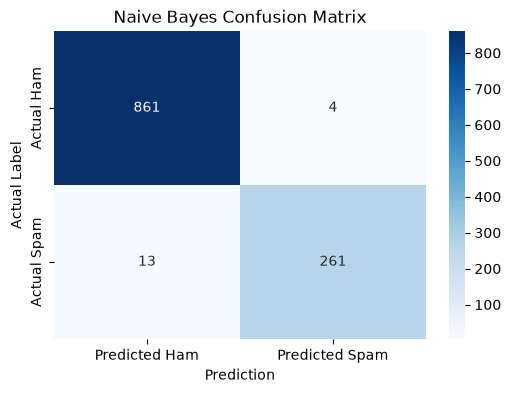

In [19]:
# Create a confusion matrix to see each correct and incorrect prediction type.

confusion_matrix_values = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix_values,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Ham", "Predicted Spam"],
    yticklabels=["Actual Ham", "Actual Spam"]
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual Label")
plt.show()

## 11. Analyze Incorrect Predictions

In [20]:
# Create a table containing each test email, its real label, and the model's prediction.

test_results = pd.DataFrame(
    {
        "actual_label": y_test,
        "predicted_label": y_pred
    }
)

# Add the original, readable email text using the preserved row indexes.
test_results["original_text"] = emails.loc[test_results.index, "text"]

# Separate the two types of errors.
false_positives = test_results[
    (test_results["actual_label"] == 0) &
    (test_results["predicted_label"] == 1)
]

false_negatives = test_results[
    (test_results["actual_label"] == 1) &
    (test_results["predicted_label"] == 0)
]

print("False positives: ", len(false_positives))
print("False negatives:", len(false_negatives))

print("\nExamples of false-positive emails:")
display(false_positives[["original_text"]].head(4))

print("\nExamples of false-negative emails:")
display(false_negatives[["original_text"]].head(5))

False positives:  4
False negatives: 13

Examples of false-positive emails:


,original_text
4264,Subject: data for moody ' s riskcalc craig an...
3720,Subject: department of energy is deploying a c...
2837,Subject: a basic idea of price - offer matchin...
2396,Subject: btrieve free ride ends network world...



Examples of false-negative emails:


,original_text
927,Subject: julie invites you to her free webcam ...
937,Subject: re : nawty locals in your area pdi s...
92,Subject: http : / / www . virtu ally - anyw...
566,Subject: blue horseshoe meet me dear reader :...
1014,Subject: mcle seminars click here to be rem...


## 12. Predict a New Email

In [22]:
def predict_email(email_text):
    """
    Predict whether a new email is spam or ham.
    """

    # Apply the same preprocessing used for the training emails.
    cleaned_text = preprocess_text(email_text)

    # Convert the cleaned email into TF-IDF features.
    # We use transform(), not fit_transform(), because the vocabulary already exists.
    email_tfidf = tfidf_vectorizer.transform([cleaned_text])

    # Predict the class: 0 for ham or 1 for spam.
    predicted_label = naive_bayes_model.predict(email_tfidf)[0]

    # Get the model's estimated probability that the email is spam.
    spam_probability = naive_bayes_model.predict_proba(email_tfidf)[0][1]

    # Convert the numerical prediction into a readable label.
    prediction = "Spam" if predicted_label == 1 else "Ham"

    print("Prediction:", prediction)
    print(f"Estimated spam probability: {spam_probability:.2%}")

In [23]:
new_email = """
Congratulations! You have won a free prize.
Click here now to claim your reward.
"""

predict_email(new_email)

Prediction: Spam
Estimated spam probability: 66.33%


In [24]:
ham_email = """
Hi team,

The project meeting is scheduled for tomorrow at 10 AM.
Please review the agenda before the meeting.

Thanks,
Aisha
"""

predict_email(ham_email)

Prediction: Ham
Estimated spam probability: 0.15%


## 13. Conclusion

This project built a Spam Mail Detector using email text data. The model classifies an email as spam or ham (non-spam).

### Dataset Preparation

- Original dataset size: 5,728 emails
- Duplicate emails removed: 33
- Cleaned dataset size: 5,695 emails
- Ham emails: 4,327
- Spam emails: 1,368

### Text Preprocessing

The email text was converted to lowercase, tokenized into words, cleaned by removing punctuation and symbols, and filtered by removing English stopwords.

### Feature Extraction

TF-IDF converted the cleaned email text into 5,000 numerical features. The vocabulary was learned only from training data to avoid data leakage.

### Model

A Multinomial Naive Bayes classifier was trained using 4,556 emails. The remaining 1,139 emails were used for testing.

### Final Results

- Accuracy: 98.51%
- Spam precision: 98.49%
- Spam recall: 95.26%
- Spam F1 score: 96.85%

The model correctly classified 1,122 out of 1,139 test emails.

### Error Analysis

- False positives: 4 ham emails incorrectly predicted as spam
- False negatives: 13 spam emails incorrectly predicted as ham

The model produced strong overall results. Future improvements could include comparing Logistic Regression, adjusting TF-IDF settings, and training with a more diverse email dataset.

## 14. Save the Trained Model

In [ ]:
# import os
# import joblib

# # Create the models folder if it does not already exist.
# os.makedirs("../models", exist_ok=True)

# # Store both the trained classifier and the fitted TF-IDF vectorizer.
# model_artifacts = {
#     "model": naive_bayes_model,
#     "vectorizer": tfidf_vectorizer
# }

# # Save the artifacts as one reusable file.
# model_path = "../models/spam_mail_detector.joblib"

# joblib.dump(model_artifacts, model_path)

# print("Model saved successfully.")
# print("Saved model path:", model_path)